# 6. Pearson Prediction Analysis
This notebook computes the Pearson correlation, MSE, and Cosine Similarity treating gene values as predictors for their corresponding protein values.
It uses threshold-based protein lists (05, 06, 07, 08) and evaluates them across TMT, iTRAQ, and LabelFree datasets.

In [9]:
import numpy as np
import pandas as pd
import joblib
import os
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

# Suppress warnings
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_theme(style="whitegrid")

In [10]:
val_data_dir = '../val_data'
pearson_dir = '../pearson proteins'

datasets = ['TMT', 'iTRAQ', 'LabelFree']
thresholds = ['05', '06', '07', '08']

# Load Omic Data
data = {}
for ds in datasets:
    rna_path = os.path.join(val_data_dir, f'{ds}_transcriptomics.joblib')
    prot_path = os.path.join(val_data_dir, f'{ds}_proteomics.joblib')
    
    if os.path.exists(rna_path) and os.path.exists(prot_path):
        rna_df = joblib.load(rna_path)
        prot_df = joblib.load(prot_path)
        
        # Ensure inner join on samples
        common_samples = rna_df.index.intersection(prot_df.index)
        data[ds] = {'rna': rna_df.loc[common_samples], 'prot': prot_df.loc[common_samples]}
        print(f"Loaded {ds}: {len(common_samples)} samples.")
    else:
        print(f"Missing data for {ds}")

# Load Protein Lists
protein_lists = {}
for th in thresholds:
    file_path = os.path.join(pearson_dir, f'protein_list_{th}.txt')
    if os.path.exists(file_path):
        with open(file_path, 'r') as f:
            prots = [line.strip() for line in f if line.strip()]
        protein_lists[th] = prots
        print(f"Loaded {len(prots)} proteins for threshold 0.{th[1]}")
    else:
        print(f"Missing file {file_path}")

Loaded TMT: 1924 samples.
Loaded iTRAQ: 276 samples.
Loaded LabelFree: 360 samples.
Loaded 2175 proteins for threshold 0.5
Loaded 1398 proteins for threshold 0.6
Loaded 786 proteins for threshold 0.7
Loaded 268 proteins for threshold 0.8


In [11]:
results = []
protein_metrics = {}

for th in thresholds:
    if th not in protein_lists:
        continue
        
    prots = protein_lists[th]
    protein_metrics[th] = {}
    target_corr = int(th) / 10.0
    
    print(f"\n{'='*50}\nEvaluating Threshold 0.{th[1]}\n{'='*50}")
    for ds in datasets:
        if ds not in data:
            continue
            
        rna_df = data[ds]['rna']
        prot_df = data[ds]['prot']
        
        common_prots = list(set(prots) & set(rna_df.columns) & set(prot_df.columns))
        
        metrics = []
        count_above_th = 0
        count_above_05 = 0
        
        for p in common_prots:
            y_pred = rna_df[p].values
            y_true = prot_df[p].values
            
            # Filter NaNs if any
            valid_idx = ~pd.isna(y_pred) & ~pd.isna(y_true)
            y_pred_valid = y_pred[valid_idx]
            y_true_valid = y_true[valid_idx]
            
            # Check varying elements avoiding true division and correlation numeric issues
            if len(y_true_valid) > 1 and np.std(y_true_valid, ddof=1) > 1e-8 and np.std(y_pred_valid, ddof=1) > 1e-8:
                corr, _ = pearsonr(y_true_valid, y_pred_valid)
            else:
                corr = np.nan
                
            if len(y_true_valid) > 0:
                mse = mean_squared_error(y_true_valid, y_pred_valid)
                cos_sim = cosine_similarity(y_true_valid.reshape(1, -1), y_pred_valid.reshape(1, -1))[0,0]
            else:
                mse = np.nan
                cos_sim = np.nan
                
            metrics.append({
                'protein': p,
                'pearson': corr,
                'mse': mse,
                'cosine': cos_sim
            })
            
            if not np.isnan(corr):
                if corr >= target_corr:
                    count_above_th += 1
                if corr >= 0.5:
                    count_above_05 += 1
                
        metrics_df = pd.DataFrame(metrics).dropna(subset=['pearson', 'mse', 'cosine'])
        protein_metrics[th][ds] = metrics_df
        
        total_eval = len(common_prots)
        if total_eval > 0:
            print(f"[{ds}] {count_above_th} / {total_eval} ({(count_above_th/total_eval)*100:.1f}%) proteins have Pearson >= {target_corr}")
            if target_corr != 0.5:
                print(f"       -> {count_above_05} / {total_eval} ({(count_above_05/total_eval)*100:.1f}%) proteins have Pearson >= 0.5")
        else:
            print(f"[{ds}] 0 / 0 proteins evaluated")

        results.append({
            'Threshold': f'0.{th[1]}',
            'Dataset': ds,
            'Evaluated Proteins': total_eval,
            'Count >= Target': count_above_th,
            'Count >= 0.5': count_above_05,
            'Mean Pearson': metrics_df['pearson'].mean(),
            'Mean MSE': metrics_df['mse'].mean(),
            'Mean Cosine': metrics_df['cosine'].mean()
        })

summary_df = pd.DataFrame(results)
display(summary_df)


Evaluating Threshold 0.5
[TMT] 7 / 1037 (0.7%) proteins have Pearson >= 0.5
[iTRAQ] 3 / 1037 (0.3%) proteins have Pearson >= 0.5
[LabelFree] 183 / 1037 (17.6%) proteins have Pearson >= 0.5

Evaluating Threshold 0.6
[TMT] 0 / 677 (0.0%) proteins have Pearson >= 0.6
       -> 6 / 677 (0.9%) proteins have Pearson >= 0.5
[iTRAQ] 1 / 677 (0.1%) proteins have Pearson >= 0.6
       -> 3 / 677 (0.4%) proteins have Pearson >= 0.5
[LabelFree] 79 / 677 (11.7%) proteins have Pearson >= 0.6
       -> 130 / 677 (19.2%) proteins have Pearson >= 0.5

Evaluating Threshold 0.7
[TMT] 0 / 373 (0.0%) proteins have Pearson >= 0.7
       -> 6 / 373 (1.6%) proteins have Pearson >= 0.5
[iTRAQ] 1 / 373 (0.3%) proteins have Pearson >= 0.7
       -> 3 / 373 (0.8%) proteins have Pearson >= 0.5
[LabelFree] 25 / 373 (6.7%) proteins have Pearson >= 0.7
       -> 84 / 373 (22.5%) proteins have Pearson >= 0.5

Evaluating Threshold 0.8
[TMT] 0 / 117 (0.0%) proteins have Pearson >= 0.8
       -> 5 / 117 (4.3%) proteins 

,Threshold,Dataset,Evaluated Proteins,Count >= Target,Count >= 0.5,Mean Pearson,Mean MSE,Mean Cosine
0,0.5,TMT,1037,7,7,0.348692,7.575433,0.346921
1,0.5,iTRAQ,1037,3,3,0.153211,0.370148,0.099891
2,0.5,LabelFree,1037,183,183,0.094649,3.034820,0.097405
3,0.6,TMT,677,0,6,0.348750,6.340705,0.346182
4,0.6,iTRAQ,677,1,3,0.158721,0.361159,0.101965
5,0.6,LabelFree,677,79,130,0.115158,2.524575,0.119402
6,0.7,TMT,373,0,6,0.346342,5.071115,0.342253
7,0.7,iTRAQ,373,1,3,0.170202,0.351052,0.110016
8,0.7,LabelFree,373,25,84,0.164281,1.910259,0.171551
9,0.8,TMT,117,0,5,0.362514,3.568259,0.354509


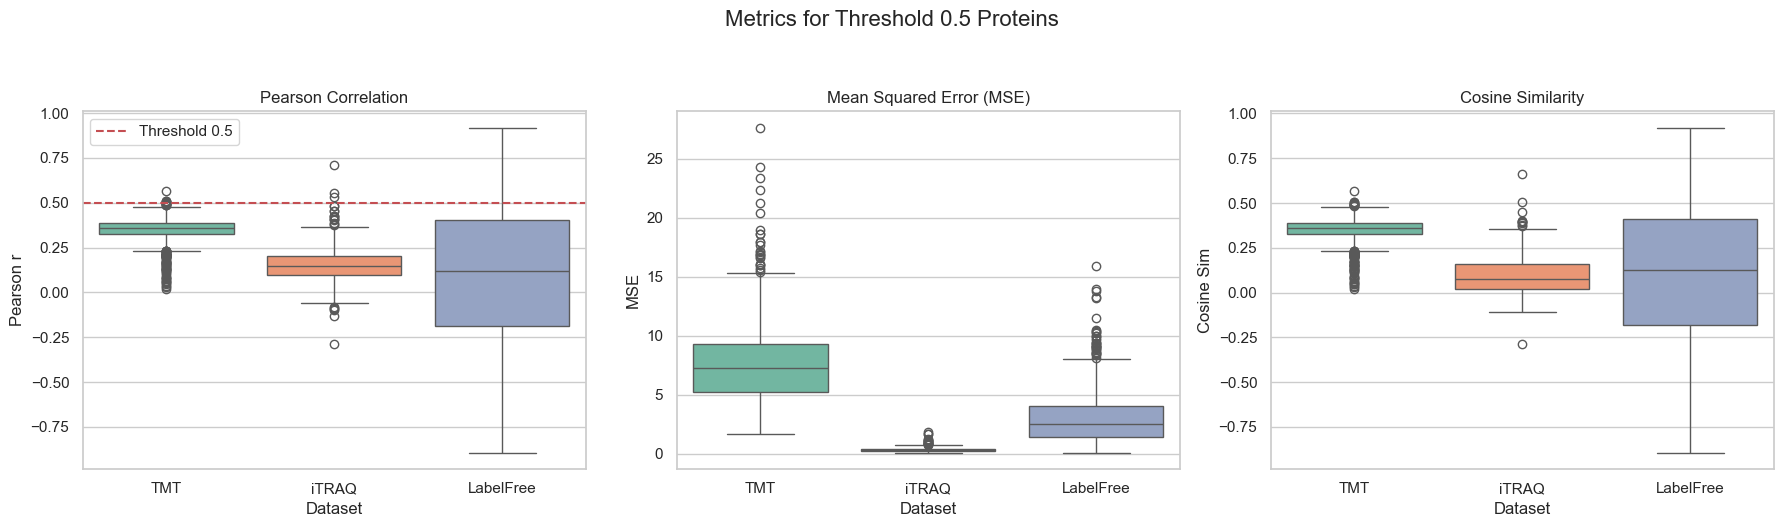

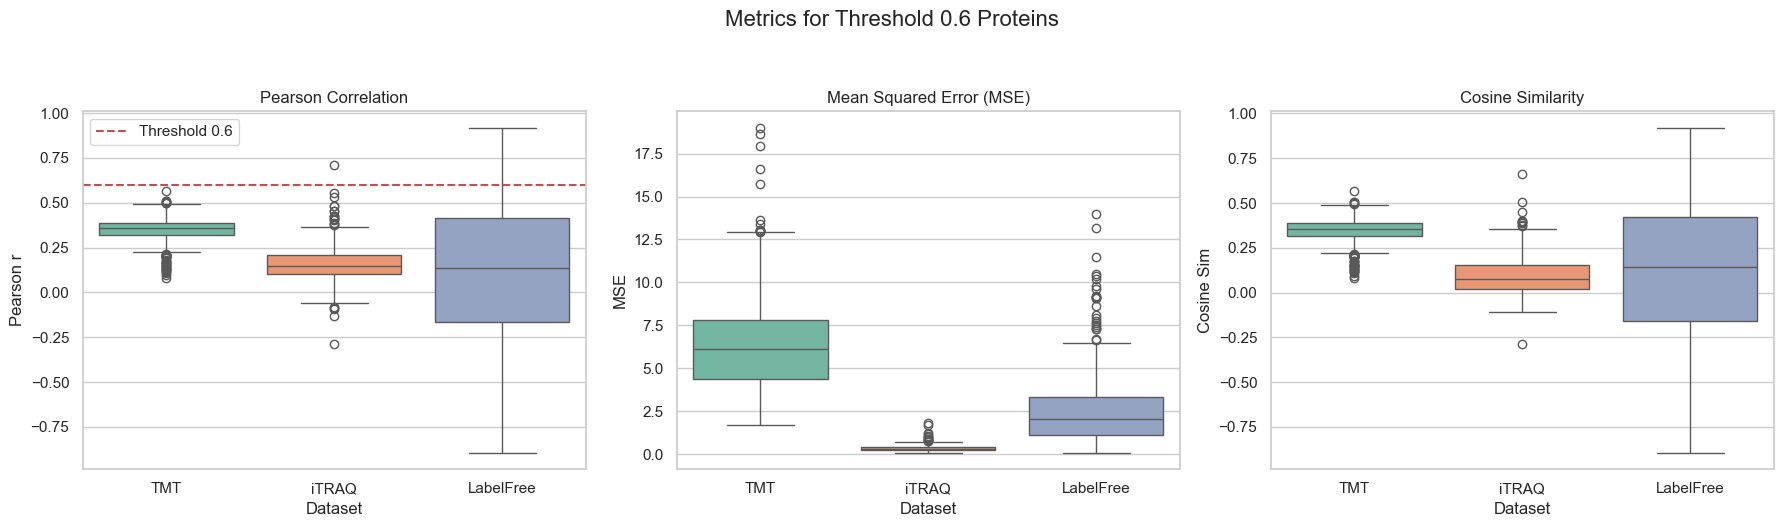

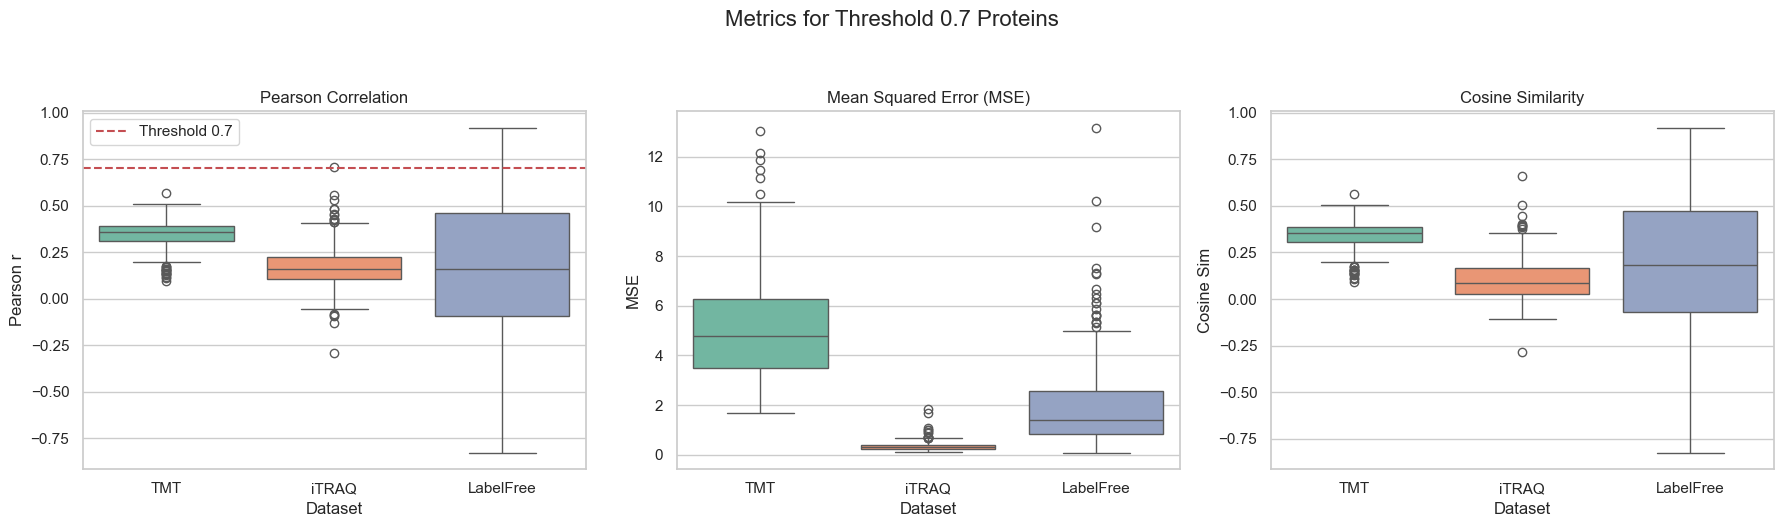

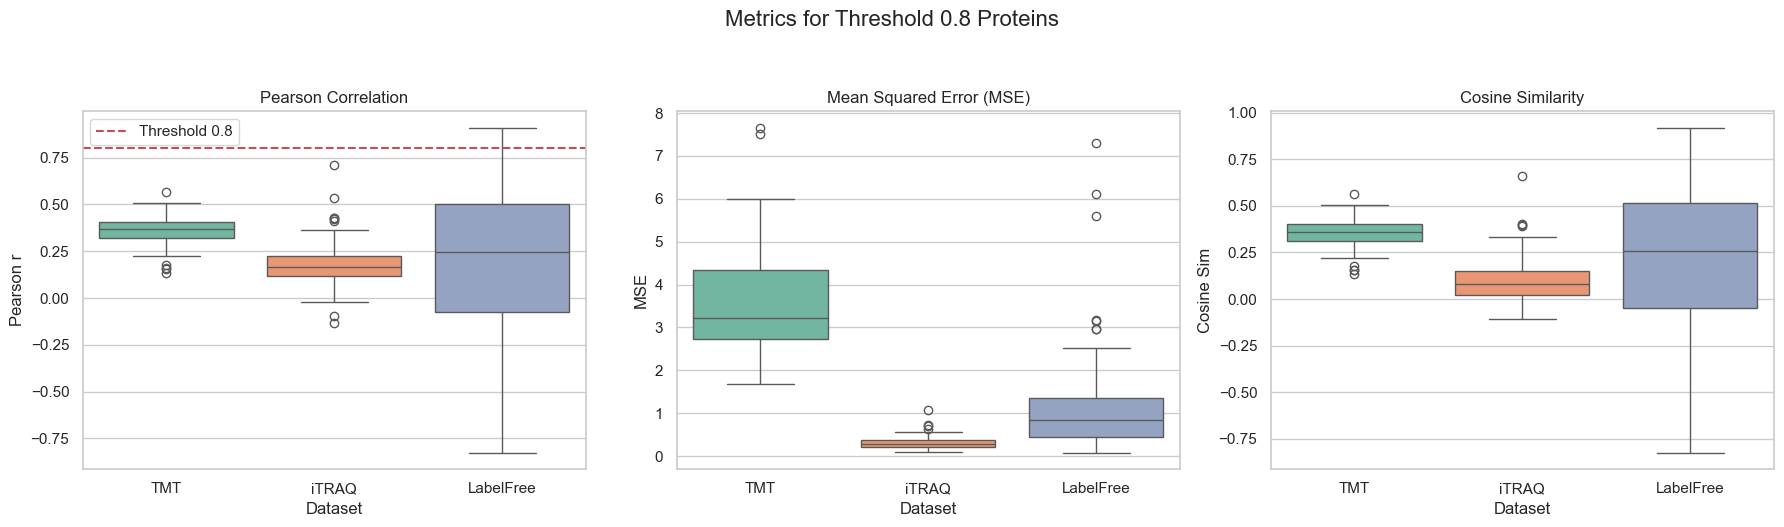

In [12]:
for th in thresholds:
    if th not in protein_metrics:
        continue
        
    # Combine datasets for seaborn
    plot_data = []
    for ds in datasets:
        if ds in protein_metrics[th]:
            df = protein_metrics[th][ds].copy()
            df['Dataset'] = ds
            plot_data.append(df)
            
    if not plot_data:
        continue
        
    combined_df = pd.concat(plot_data, ignore_index=True)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Metrics for Threshold 0.{th[1]} Proteins', y=1.05, fontsize=16)
    
    # Pearson Plot
    sns.boxplot(data=combined_df, x='Dataset', hue='Dataset', y='pearson', ax=axes[0], palette='Set2', legend=False)
    axes[0].axhline(y=int(th)/10.0, color='r', linestyle='--', label=f'Threshold 0.{th[1]}')
    axes[0].set_title('Pearson Correlation')
    axes[0].set_ylabel('Pearson r')
    
    # create customized legend for axhline
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        axes[0].legend(handles=handles, labels=labels)
    
    # MSE Plot
    sns.boxplot(data=combined_df, x='Dataset', hue='Dataset', y='mse', ax=axes[1], palette='Set2', legend=False)
    axes[1].set_title('Mean Squared Error (MSE)')
    axes[1].set_ylabel('MSE')
    
    # Cosine Plot
    sns.boxplot(data=combined_df, x='Dataset', hue='Dataset', y='cosine', ax=axes[2], palette='Set2', legend=False)
    axes[2].set_title('Cosine Similarity')
    axes[2].set_ylabel('Cosine Sim')
    
    plt.tight_layout()
    plt.show()